# Diagnóstico IX.1.2 — Agentic-RAG + gpt-5-nano y datos faltantes

Este notebook replica el diagnóstico que sostiene los artefactos de esta carpeta. **No modifica los archivos fuente**: todas las tablas y figuras se escriben en `salidas/` y `figuras/`, y la revisión manual se realiza en `revision_manual/`.

Objetivo: separar tres problemas que el manuscrito original trataba como uno solo:

1. las 27 medias ausentes por un problema de join entre `subpregunta` vacía y `0`;
2. las salidas no sustantivas de Agentic-RAG + gpt-5-nano;
3. las puntuaciones que algunos jueces asignaron a salidas vacías o no respondidas.

La conclusión preliminar es que la celda nano no muestra una degradación uniforme: muestra un **modo de fallo de respuesta**. Cuando responde, su calidad es alta; el problema es que no responde en 41 de 79 unidades.


## Actualización: revisión manual aceptada (2026-11-12)

Este notebook documenta la **clasificación automática**, que produce 57 salidas no sustantivas. La revisión manual aceptada incorporó `R052` como abstención explícita y fijó **58 salidas no sustantivas**.

Para el reanálisis IX.1.1 debe usarse `salidas/14_dataset_categoria_final.csv`; el resumen final está en `salidas/15_resumen_por_celda_final.csv` y las figuras finales en `figuras_final/`. La tabla automática `salidas/01_dataset_derivado_711.csv` se conserva como histórico reproducible.


In [1]:
from pathlib import Path
import sys
import pandas as pd

def find_root(start):
    for path in [start, *start.parents]:
        if (path / 'codigo_experimentos').exists() and (path / 'manuscrito').exists():
            return path
    raise RuntimeError('No se encontró la raíz del repositorio')

ROOT = find_root(Path.cwd())
CORRECTION = ROOT / 'analisis-valoracion-jurado' / 'correccion-02-diagnostico-gpt-5-nano'
sys.path.insert(0, str(CORRECTION / 'src'))
import diagnostico as dg

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 220)
print('Raíz:', ROOT)
print('Corrección:', CORRECTION)


Raíz: /mnt/d/OneDrive/ex_dropbox/tesis-maestria-data-mining
Corrección: /mnt/d/OneDrive/ex_dropbox/tesis-maestria-data-mining/analisis-valoracion-jurado/correccion-02-diagnostico-gpt-5-nano


## 1. Construcción del dataset derivado

Se normalizan las claves `None`/vacío/`0` **solo en memoria** y se conservan las columnas originales. El dataset tiene 711 observaciones, 79 unidades y 9 celdas.


In [2]:
data, responses, metrics, judges, logs = dg.build_dataset()
print('Observaciones:', len(data))
print('Unidades:', data['obs_id'].nunique())
print('Casos:', data['q'].nunique())
print('Celdas:', data.groupby(['estrategia', 'modelo']).ngroups)
print('Filas de jueces:', len(judges))
print('Filas por celda:')
print(data.groupby(['estrategia', 'modelo']).size().to_string())


Observaciones: 711
Unidades: 79
Casos: 25
Celdas: 9
Filas de jueces: 2133
Filas por celda:
estrategia                 modelo    
llm_responses_agentic_rag  gpt-5         79
                           gpt-5-mini    79
                           gpt-5-nano    79
llm_responses_base_rag     gpt-5         79
                           gpt-5-mini    79
                           gpt-5-nano    79
llm_responses_no_rag       gpt-5         79
                           gpt-5-mini    79
                           gpt-5-nano    79


## 2. Resumen por celda

`n_no_sustantiva` incluye vacías, solo espacios, abstenciones explícitas, errores explícitos, truncadas e indeterminadas. Los intervalos de la tasa de fallo son Wilson 95%.


In [3]:
summary = dg.summarize_cells(data)
cols = [
    'estrategia_corta', 'modelo', 'n_sustantiva', 'n_no_sustantiva',
    'n_vacia', 'n_solo_espacios', 'n_abstencion_explicita', 'n_truncada',
    'n_indeterminada', 'tasa_no_sustantiva',
    'tasa_no_sustantiva_ic95_inf', 'tasa_no_sustantiva_ic95_sup',
    'media_original', 'mediana_original', 'media_fallo_cero',
    'mediana_fallo_cero', 'media_exclusion', 'mediana_exclusion', 'n_exclusion',
]
display(summary[cols].round(3))


,estrategia_corta,modelo,n_sustantiva,n_no_sustantiva,n_vacia,n_solo_espacios,n_abstencion_explicita,n_truncada,n_indeterminada,tasa_no_sustantiva,tasa_no_sustantiva_ic95_inf,tasa_no_sustantiva_ic95_sup,media_original,mediana_original,media_fallo_cero,mediana_fallo_cero,media_exclusion,mediana_exclusion,n_exclusion
0,sin_rag,gpt-5-nano,78,1,0,0,1,0,0,0.013,0.002,0.068,0.565,0.583,0.565,0.583,0.573,0.583,78
1,sin_rag,gpt-5-mini,65,14,0,0,14,0,0,0.177,0.109,0.276,0.336,0.250,0.326,0.250,0.396,0.333,65
2,sin_rag,gpt-5,79,0,0,0,0,0,0,0.000,0.000,0.046,0.725,0.833,0.725,0.833,0.725,0.833,79
3,rag_basico,gpt-5-nano,79,0,0,0,0,0,0,0.000,0.000,0.046,0.599,0.583,0.599,0.583,0.599,0.583,79
4,rag_basico,gpt-5-mini,79,0,0,0,0,0,0,0.000,0.000,0.046,0.650,0.667,0.650,0.667,0.650,0.667,79
5,rag_basico,gpt-5,79,0,0,0,0,0,0,0.000,0.000,0.046,0.707,0.833,0.707,0.833,0.707,0.833,79
6,agentic_rag,gpt-5-nano,38,41,27,1,2,1,10,0.519,0.411,0.626,0.415,0.250,0.395,0.000,0.820,0.958,38
7,agentic_rag,gpt-5-mini,78,1,0,0,0,0,1,0.013,0.002,0.068,0.788,1.000,0.788,1.000,0.798,1.000,78
8,agentic_rag,gpt-5,79,0,0,0,0,0,0,0.000,0.000,0.046,0.812,1.000,0.812,1.000,0.812,1.000,79


## 3. Celda Agentic-RAG + gpt-5-nano

La celda contiene 38 respuestas sustantivas y 41 no sustantivas. Las no sustantivas incluyen 27 vacías, 10 indeterminadas (mensajes de proceso, marcadores de prueba o mensaje interno), 2 abstenciones explícitas, 1 truncada y 1 con solo espacios.


In [4]:
nano = data[(data['estrategia'] == 'llm_responses_agentic_rag') & (data['modelo'] == 'gpt-5-nano')].copy()
print(nano['categoria'].value_counts().to_string())
print('\nResumen:')
print(summary[(summary['estrategia'] == 'llm_responses_agentic_rag') & (summary['modelo'] == 'gpt-5-nano')][cols].round(3).to_string(index=False))
print('\nRespuestas sustantivas:')
print(nano[nano['categoria'] == 'sustantiva']['puntaje_original_rubric'].describe().round(3).to_string())


categoria
sustantiva              38
vacia                   27
indeterminada           10
abstencion_explicita     2
truncada                 1
solo_espacios            1

Resumen:
estrategia_corta     modelo  n_sustantiva  n_no_sustantiva  n_vacia  n_solo_espacios  n_abstencion_explicita  n_truncada  n_indeterminada  tasa_no_sustantiva  tasa_no_sustantiva_ic95_inf  tasa_no_sustantiva_ic95_sup  media_original  mediana_original  media_fallo_cero  mediana_fallo_cero  media_exclusion  mediana_exclusion  n_exclusion
     agentic_rag gpt-5-nano            38               41       27                1                       2           1               10               0.519                        0.411                        0.626           0.415              0.25             0.395                 0.0             0.82              0.958           38

Respuestas sustantivas:
count    38.000
mean      0.820
std       0.260
min       0.000
25%       0.667
50%       0.958
75%       1.000
max    

In [5]:
cols_nano = [
    'obs_id', 'categoria', 'subcategoria', 'respuesta_obtenida',
    'longitud_caracteres', 'puntaje_original_rubric', 'puntaje_fallo_cero',
    'law_final_result_count', 'law_selected_docs_first',
    'retrieval_history_count', 'law_output_tokens', 'law_reasoning_tokens',
    'juez_no_cero_en_no_sustantiva',
]
display(nano[nano['categoria'] != 'sustantiva'][cols_nano])


,obs_id,categoria,subcategoria,respuesta_obtenida,longitud_caracteres,puntaje_original_rubric,puntaje_fallo_cero,law_final_result_count,law_selected_docs_first,retrieval_history_count,law_output_tokens,law_reasoning_tokens,juez_no_cero_en_no_sustantiva
20,Q01_03,vacia,texto_original_vacio,,0,0.000000,0.0,1.0,7.0,6.0,2813.0,2688.0,False
65,Q03_02,indeterminada,mensaje_de_proceso,Por favor espera mientras analizo la normativa...,82,0.000000,0.0,1.0,5.0,6.0,3679.0,3520.0,False
74,Q03_03,indeterminada,mensaje_de_proceso,I will consult the relevant legal sources to i...,143,0.000000,0.0,1.0,8.0,6.0,4592.0,4480.0,False
83,Q04_01,vacia,texto_original_vacio,,0,0.000000,0.0,1.0,12.0,6.0,4999.0,4864.0,False
101,Q04_03,vacia,texto_original_vacio,,0,0.000000,0.0,1.0,6.0,6.0,5147.0,5056.0,False
110,Q05_01,vacia,texto_original_vacio,,0,0.333333,0.0,1.0,3.0,6.0,5636.0,5376.0,True
119,Q05_02,vacia,texto_original_vacio,,0,0.000000,0.0,1.0,10.0,6.0,3004.0,2880.0,False
128,Q05_03,vacia,texto_original_vacio,,0,0.000000,0.0,1.0,7.0,5.0,7015.0,6656.0,False
137,Q05_04,truncada,json_incompleto,{,1,0.000000,0.0,1.0,11.0,6.0,5639.0,5504.0,False
146,Q06_01,vacia,texto_original_vacio,,0,0.000000,0.0,1.0,5.0,6.0,2143.0,1920.0,False


## 4. Logs: el fallo no es falta de recuperación ni truncamiento

Los 79 logs de gpt-5-nano contienen una llamada a `retrieve_relevant_documents` y al menos una llamada a `final_result` (77 con una sola y 2 con más de una); el `finish_reason` del especialista es `tool_call` en los 79 casos. La diferencia está en el argumento `response_text` del `final_result`: vacío, con espacios o con un marcador no respondido.

Además, las salidas vacías no se explican por falta de documentos: tienen entre 1 y 12 documentos seleccionados y entre 575 y 7.015 tokens de salida. No hay evidencia de agotamiento del límite de tokens en los logs.


In [6]:
logs_summary = dg.build_logs_summary(logs)
display(logs_summary)

print('\nDetalle de logs de la celda nano:')
cols_logs = [
    'obs_id', 'categoria', 'law_final_result_count', 'law_selected_docs_first',
    'law_selected_docs_max', 'retrieval_history_count', 'law_output_tokens',
    'law_reasoning_tokens', 'law_finish_reasons_json',
]
display(nano[cols_logs].head(15))


,modelo,n,n_final_texto_vacio,n_final_texto_no_vacio,n_final_result_count_1,n_final_result_count_mayor_1,law_finish_reasons,retrieval_finish_reasons,hist_count_min,hist_count_mediana,hist_count_max,selected_docs_min,selected_docs_mediana,selected_docs_max,law_output_tokens_mediana,law_output_tokens_min,law_output_tokens_max,law_reasoning_tokens_mediana
0,gpt-5-nano,79,28,51,77,2,tool_call → tool_call (79),tool_call → tool_call → tool_call → tool_call ...,2,6.0,6,1.0,5.0,12.0,3949.0,575.0,9228.0,3456.0
1,gpt-5-mini,79,0,79,79,0,tool_call → tool_call (79),tool_call → tool_call → stop (35); tool_call →...,3,6.0,6,1.0,6.0,12.0,2399.0,575.0,4595.0,1344.0
2,gpt-5,79,0,79,79,0,tool_call → tool_call (78); tool_call → tool_c...,tool_call → tool_call → stop (24); tool_call →...,1,6.0,9,1.0,7.0,16.0,3691.0,1296.0,6860.0,3072.0



Detalle de logs de la celda nano:


,obs_id,categoria,law_final_result_count,law_selected_docs_first,law_selected_docs_max,retrieval_history_count,law_output_tokens,law_reasoning_tokens,law_finish_reasons_json
2,Q01_01,sustantiva,1.0,8.0,8.0,6.0,7395.0,6592.0,"[""tool_call"", ""tool_call""]"
11,Q01_02,sustantiva,1.0,6.0,6.0,6.0,4237.0,3904.0,"[""tool_call"", ""tool_call""]"
20,Q01_03,vacia,1.0,7.0,7.0,6.0,2813.0,2688.0,"[""tool_call"", ""tool_call""]"
29,Q02_01,sustantiva,1.0,3.0,3.0,4.0,5620.0,5248.0,"[""tool_call"", ""tool_call""]"
38,Q02_02,sustantiva,1.0,6.0,6.0,6.0,3949.0,3584.0,"[""tool_call"", ""tool_call""]"
47,Q02_03,sustantiva,1.0,6.0,6.0,6.0,5605.0,4736.0,"[""tool_call"", ""tool_call""]"
56,Q03_01,sustantiva,1.0,5.0,5.0,6.0,5556.0,4608.0,"[""tool_call"", ""tool_call""]"
65,Q03_02,indeterminada,1.0,5.0,5.0,6.0,3679.0,3520.0,"[""tool_call"", ""tool_call""]"
74,Q03_03,indeterminada,1.0,8.0,8.0,6.0,4592.0,4480.0,"[""tool_call"", ""tool_call""]"
83,Q04_01,vacia,1.0,12.0,12.0,6.0,4999.0,4864.0,"[""tool_call"", ""tool_call""]"


## 5. Las 27 medias ausentes son un problema de join

En `part_i/combined_metrics_for_analysis.csv` las unidades 23, 24 y 25 tienen `nro_subpregunta` vacío. En `part_i/final_judge_results.csv` tienen `numero_subpregunta = 0`. El join de `part_j/01_exploracion_descriptiva_correlacion.ipynb` no las encuentra.

No son 27 fallos de generación: son 3 unidades × 9 configuraciones. Las 27 tienen tres evaluaciones de jueces y textos sustantivos. Al normalizar la clave se recuperan las 711 observaciones y 2.133 evaluaciones.


In [7]:
join_audit = dg.build_join_audit(data, judges)
print('Filas auditadas:', len(join_audit))
print('Combinaciones q × celda:', join_audit.groupby(['q', 'estrategia', 'modelo']).ngroups)
print('Filas con media original ausente:', join_audit['respuesta_correcta_avg_csv_original'].isna().sum())
display(join_audit[['q', 'obs_id', 'sub_en_metrics', 'sub_en_judges', 'estrategia', 'modelo', 'n_filas_juez', 'respuesta_correcta_avg_csv_original', 'respuesta_correcta_rubric_fix']].head(12))


Filas auditadas: 27
Combinaciones q × celda: 27
Filas con media original ausente: 27


,q,obs_id,sub_en_metrics,sub_en_judges,estrategia,modelo,n_filas_juez,respuesta_correcta_avg_csv_original,respuesta_correcta_rubric_fix
0,23,Q23_00,<vacío>,0,llm_responses_no_rag,gpt-5-nano,3,NaN,0.000000
1,23,Q23_00,<vacío>,0,llm_responses_no_rag,gpt-5-mini,3,NaN,0.250000
2,23,Q23_00,<vacío>,0,llm_responses_no_rag,gpt-5,3,NaN,1.000000
3,23,Q23_00,<vacío>,0,llm_responses_base_rag,gpt-5-nano,3,NaN,1.000000
4,23,Q23_00,<vacío>,0,llm_responses_base_rag,gpt-5-mini,3,NaN,1.000000
5,23,Q23_00,<vacío>,0,llm_responses_base_rag,gpt-5,3,NaN,1.000000
6,23,Q23_00,<vacío>,0,llm_responses_agentic_rag,gpt-5-nano,3,NaN,0.916667
7,23,Q23_00,<vacío>,0,llm_responses_agentic_rag,gpt-5-mini,3,NaN,1.000000
8,23,Q23_00,<vacío>,0,llm_responses_agentic_rag,gpt-5,3,NaN,1.000000
9,24,Q24_00,<vacío>,0,llm_responses_no_rag,gpt-5-nano,3,NaN,0.166667


## 6. Jueces sobre salidas no sustantivas

Hay 57 observaciones no sustantivas en todo el experimento, con 171 evaluaciones de jueces. Algunos jueces asignaron puntajes positivos a salidas vacías o a mensajes de proceso, y en varios casos la justificación cita artículos que no están en la respuesta. Esto no demuestra que el juez sea inválido en general, pero sí que sus puntajes sobre salidas no sustantivas no deben tratarse como medición de calidad.


In [8]:
judge_audit = dg.build_judge_audit(data, judges)
print('Filas juez no sustantivas:', len(judge_audit))
print('Puntajes de corrección no cero:', int(judge_audit['puntaje_correcta_no_cero'].sum()))
print('Puntajes legales no cero:', int(judge_audit['puntaje_legal_no_cero'].sum()))
print('Combinaciones celda-unidad con al menos un puntaje no cero:', judge_audit.groupby(['obs_id', 'estrategia', 'modelo'])['puntaje_correcta_no_cero'].any().sum())
print('Unidades distintas con al menos un puntaje no cero:', judge_audit[judge_audit['puntaje_correcta_no_cero']]['obs_id'].nunique())
display(judge_audit[judge_audit['puntaje_correcta_no_cero']][[
    'obs_id', 'estrategia', 'modelo', 'categoria', 'modelo_juez',
    'score_respuesta_correcta', 'score_precision_legal',
    'reason_respuesta_correcta', 'reason_precision_legal',
]])


Filas juez no sustantivas: 171
Puntajes de corrección no cero: 11
Puntajes legales no cero: 5
Combinaciones celda-unidad con al menos un puntaje no cero: 9
Unidades distintas con al menos un puntaje no cero: 8


,obs_id,estrategia,modelo,categoria,modelo_juez,score_respuesta_correcta,score_precision_legal,reason_respuesta_correcta,reason_precision_legal
12,Q03_03,llm_responses_no_rag,gpt-5-mini,abstencion_explicita,openrouter_deepseek_deepseek-chat-v3-1,0.25,0.0,La respuesta del modelo no proporciona informa...,La respuesta no cita ningún artículo relevante...
22,Q05_01,llm_responses_agentic_rag,gpt-5-nano,vacia,openrouter_deepseek_deepseek-chat-v3-1,1.0,0.0,La respuesta proporcionada está completamente ...,El output está completamente vacío y no contie...
51,Q07_01,llm_responses_no_rag,gpt-5-mini,abstencion_explicita,openrouter_deepseek_deepseek-chat-v3-1,0.5,0.0,La respuesta del modelo reconoce correctamente...,La respuesta no cita ningún artículo específic...
64,Q08_01,llm_responses_agentic_rag,gpt-5-nano,vacia,openrouter_deepseek_deepseek-chat-v3-1,0.85,0.0,La respuesta proporcionada por el usuario abor...,"El output está completamente vacío, no contien..."
70,Q08_03,llm_responses_no_rag,gpt-5-mini,abstencion_explicita,grok_4_1_fast_free,0.25,0.0,La respuesta no proporciona ni explica el proc...,La respuesta no cita ningún artículo relevante...
71,Q08_03,llm_responses_agentic_rag,gpt-5-nano,indeterminada,openrouter_deepseek_deepseek-chat-v3-1,1.0,0.0,La respuesta proporcionada es completamente co...,El output proporcionado no cita ningún artícul...
73,Q08_03,llm_responses_agentic_rag,gpt-5-nano,indeterminada,openrouter_moonshotai_kimi-k2-0905,1.0,0.0,La respuesta es completamente correcta y preci...,La respuesta no cita ningún artículo específic...
82,Q10_01,llm_responses_agentic_rag,gpt-5-nano,vacia,openrouter_deepseek_deepseek-chat-v3-1,0.9,0.0,"Según el artículo 201 del Código de Minería, l...",El output está vacío y no cita ningún artículo...
130,Q15_03,llm_responses_no_rag,gpt-5-mini,abstencion_explicita,openrouter_deepseek_deepseek-chat-v3-1,0.75,0.0,La respuesta es mayormente correcta pero conti...,El output no cita ningún artículo relevante de...
169,Q22_02,llm_responses_no_rag,gpt-5-mini,abstencion_explicita,openrouter_deepseek_deepseek-chat-v3-1,0.25,0.0,La respuesta del modelo no proporciona la info...,La respuesta no cita ningún artículo del Códig...


## 7. Sensibilidad: fallo = 0, exclusión y comparación descriptiva

La comparación principal de IX.1.1 se hará con el modelo ordinal mixto. Aquí se muestra la sensibilidad descriptiva de la celda nano. La exclusión usa solo unidades con respuesta sustantiva en ambas estrategias: es una submuestra seleccionada y no debe interpretarse como el efecto causal de la estrategia.


In [9]:
sensitivity = dg.build_sensitivity(data)
display(sensitivity[sensitivity['modelo'] == 'gpt-5-nano'][[
    'estrategia_1', 'estrategia_2', 'escenario', 'n_pares',
    'media_diferencia', 'mediana_diferencia', 'p_wilcoxon_exploratorio', 'nota',
]])


,estrategia_1,estrategia_2,escenario,n_pares,media_diferencia,mediana_diferencia,p_wilcoxon_exploratorio,nota
0,llm_responses_agentic_rag,llm_responses_base_rag,original,79,-0.184599,-0.166667,0.001525,diferencia = estrategia_1 - estrategia_2; p si...
1,llm_responses_agentic_rag,llm_responses_base_rag,fallo_cero,79,-0.204641,-0.166667,0.000655,diferencia = estrategia_1 - estrategia_2; p si...
2,llm_responses_agentic_rag,llm_responses_base_rag,solo_fallos_tecnicos_cero,79,-0.204641,-0.166667,0.000655,diferencia = estrategia_1 - estrategia_2; p si...
3,llm_responses_agentic_rag,llm_responses_base_rag,exclusion,38,0.182018,0.125000,0.002098,exclusion usa solo unidades con respuesta sust...
4,llm_responses_agentic_rag,llm_responses_no_rag,original,79,-0.150844,-0.166667,0.004427,diferencia = estrategia_1 - estrategia_2; p si...
5,llm_responses_agentic_rag,llm_responses_no_rag,fallo_cero,79,-0.170886,-0.250000,0.001875,diferencia = estrategia_1 - estrategia_2; p si...
6,llm_responses_agentic_rag,llm_responses_no_rag,solo_fallos_tecnicos_cero,79,-0.170886,-0.250000,0.001875,diferencia = estrategia_1 - estrategia_2; p si...
7,llm_responses_agentic_rag,llm_responses_no_rag,exclusion,38,0.212719,0.125000,0.002019,exclusion usa solo unidades con respuesta sust...
8,llm_responses_base_rag,llm_responses_no_rag,original,79,0.033755,-0.083333,0.985246,diferencia = estrategia_1 - estrategia_2; p si...
9,llm_responses_base_rag,llm_responses_no_rag,fallo_cero,79,0.033755,-0.083333,0.985246,diferencia = estrategia_1 - estrategia_2; p si...


## 8. Comparación de medianas con el manuscrito

La Tabla 11 del manuscrito se calculó sobre 76 observaciones por celda, no sobre 79. Al recuperar las 27 medias ausentes cambian varias medianas. Las columnas `fallo_cero` y `solo_fallos_tecnicos_cero` muestran cuánto depende el resultado del tratamiento de las salidas no sustantivas.


In [10]:
manuscript = dg.build_manuscript_comparison(data, metrics)
display(manuscript.round(3))


,estrategia,estrategia_corta,modelo,mediana_manuscrito_tabla11,n_csv_original,mediana_csv_original,mediana_corregida_79_jueces_original,mediana_fallo_cero,mediana_solo_fallos_tecnicos_cero,mediana_exclusion,n_exclusion,n_no_sustantiva
0,llm_responses_no_rag,sin_rag,gpt-5-nano,0.583,76,0.583,0.583,0.583,0.583,0.583,78,1
1,llm_responses_no_rag,sin_rag,gpt-5-mini,0.333,76,0.333,0.250,0.250,0.250,0.333,65,14
2,llm_responses_no_rag,sin_rag,gpt-5,0.833,76,0.833,0.833,0.833,0.833,0.833,79,0
3,llm_responses_base_rag,rag_basico,gpt-5-nano,0.583,76,0.583,0.583,0.583,0.583,0.583,79,0
4,llm_responses_base_rag,rag_basico,gpt-5-mini,0.625,76,0.625,0.667,0.667,0.667,0.667,79,0
5,llm_responses_base_rag,rag_basico,gpt-5,0.833,76,0.833,0.833,0.833,0.833,0.833,79,0
6,llm_responses_agentic_rag,agentic_rag,gpt-5-nano,0.083,76,0.083,0.250,0.000,0.000,0.958,38,41
7,llm_responses_agentic_rag,agentic_rag,gpt-5-mini,0.917,76,0.917,1.000,1.000,1.000,1.000,78,1
8,llm_responses_agentic_rag,agentic_rag,gpt-5,0.958,76,0.958,1.000,1.000,1.000,1.000,79,0


## 9. Sin RAG: gpt-5-nano frente a gpt-5-mini

El orden observado debe describirse, no explicarse causalmente con la “capacidad” del modelo. gpt-5-mini presenta 14 abstenciones explícitas en esta estrategia; aun excluyéndolas, su mediana es inferior a la de nano.


In [11]:
no_rag = dg.build_no_rag_descriptive(data)
display(no_rag.round(3))

,modelo,n,n_sustantiva,n_abstencion_explicita,n_otras_no_sustantivas,media_original,mediana_original,q1_original,q3_original,media_solo_sustantivas,mediana_solo_sustantivas,proporcion_score_ge_075,mediana_longitud,proporcion_menciona_articulo,proporcion_menciona_limitacion,mediana_reasoning_tokens
0,gpt-5-nano,79,78,1,0,0.565,0.583,0.417,0.75,0.573,0.583,0.329,2817.0,0.57,0.203,5376.0
1,gpt-5-mini,79,65,14,0,0.336,0.250,0.083,0.50,0.396,0.333,0.139,2392.0,1.00,0.772,1408.0


## 10. Figuras

Las figuras están en `figuras/` en PDF y PNG. Se muestran aquí las principales.


01_composicion_respuestas_por_celda.png


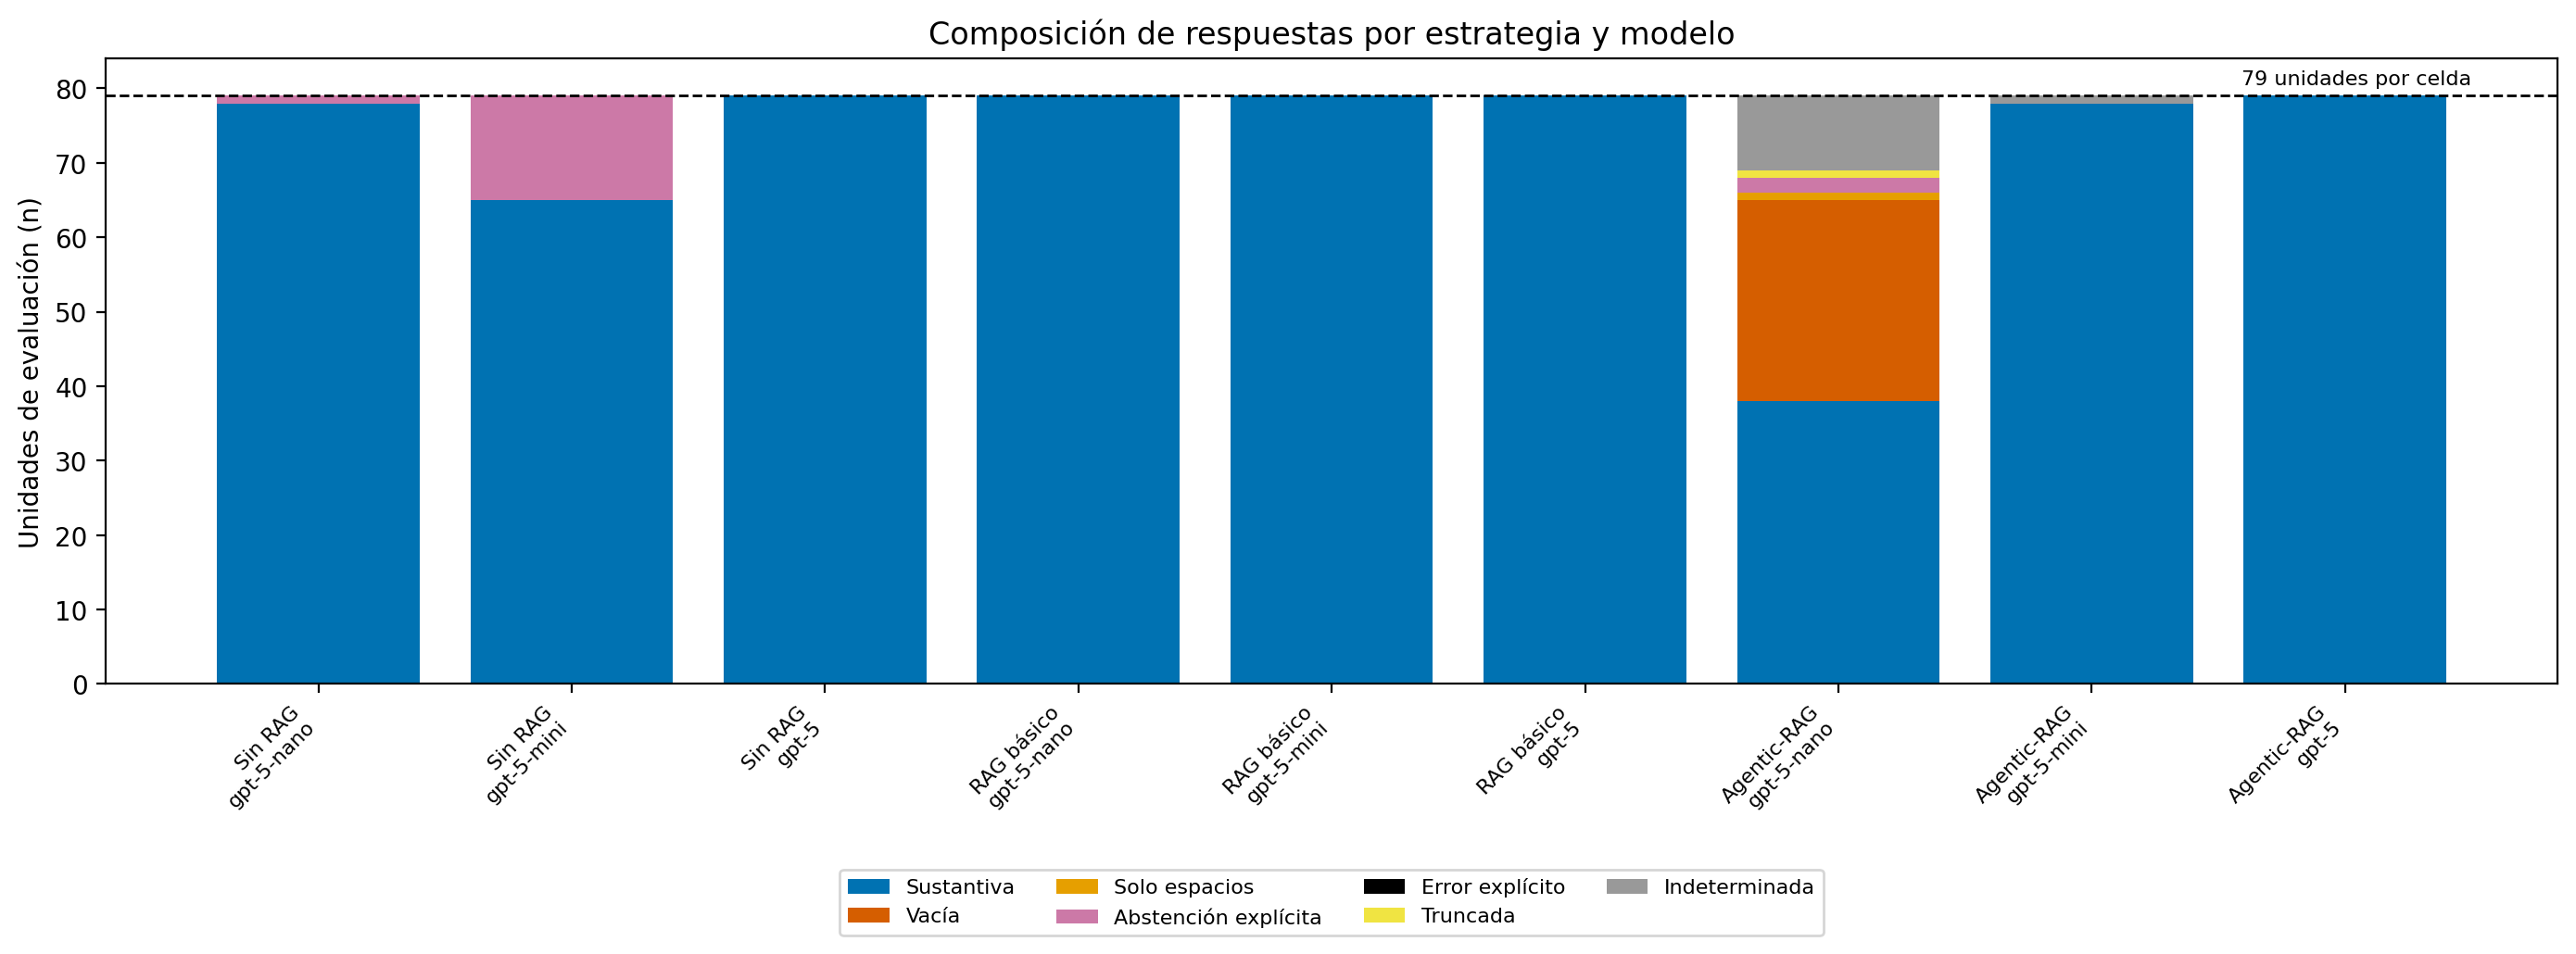

02_tasas_fallo_por_celda.png


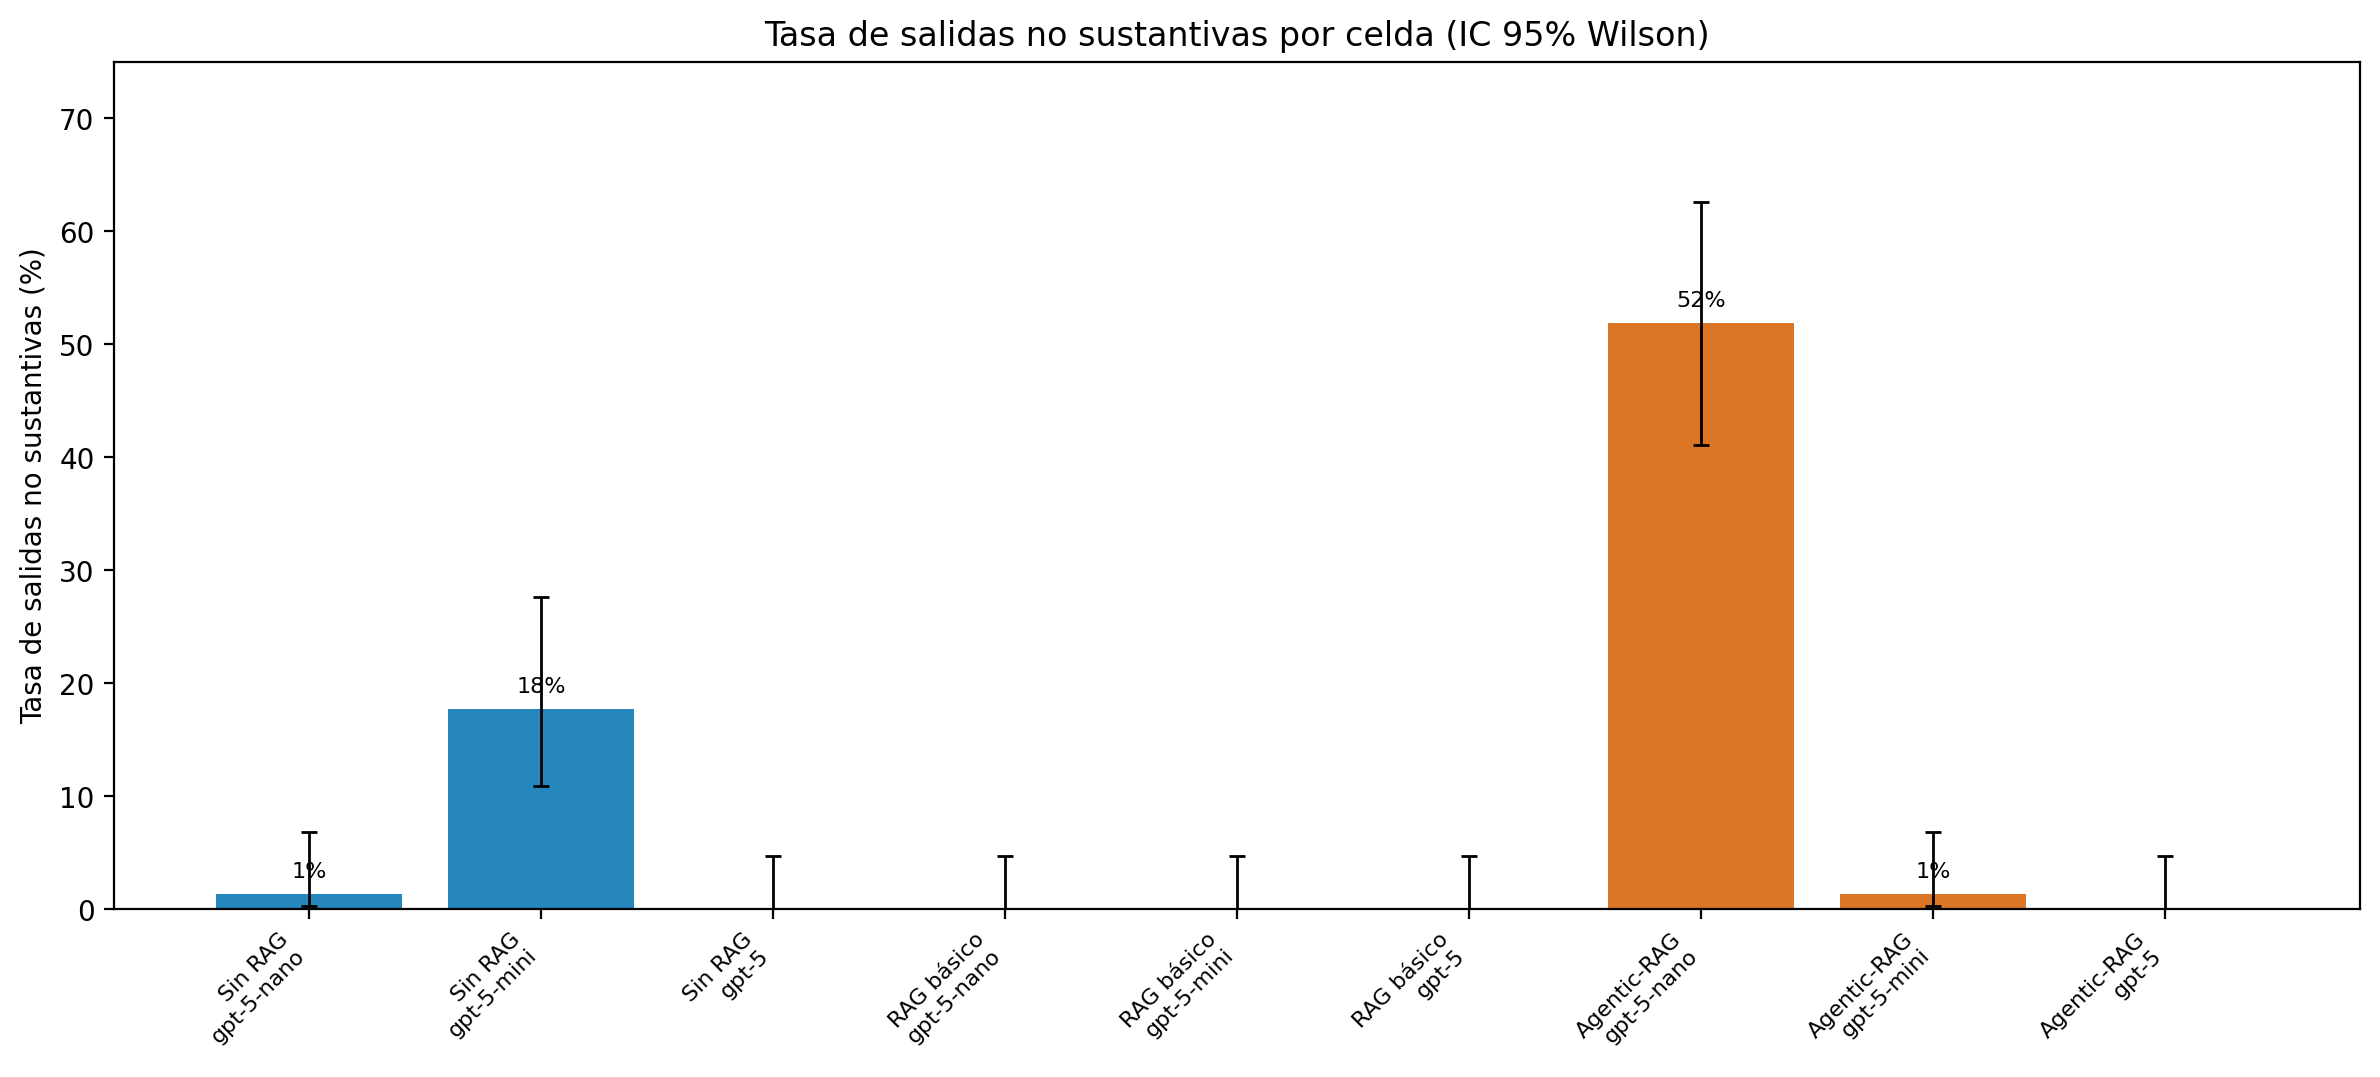

03_estados_nano_agentic.png


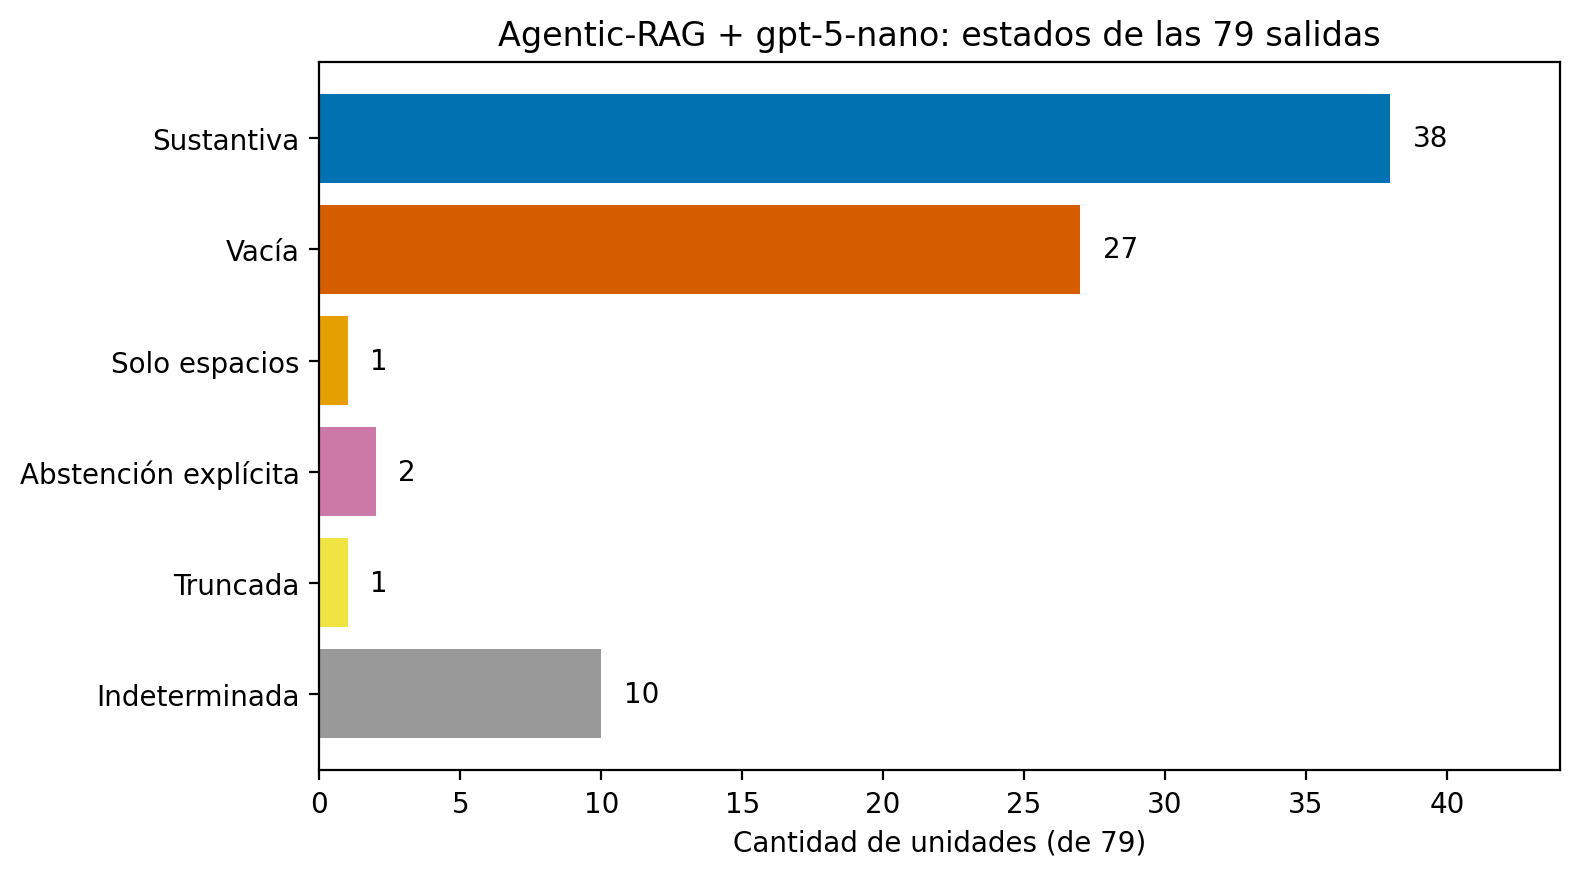

04_puntajes_jueces_salidas_no_sustantivas.png


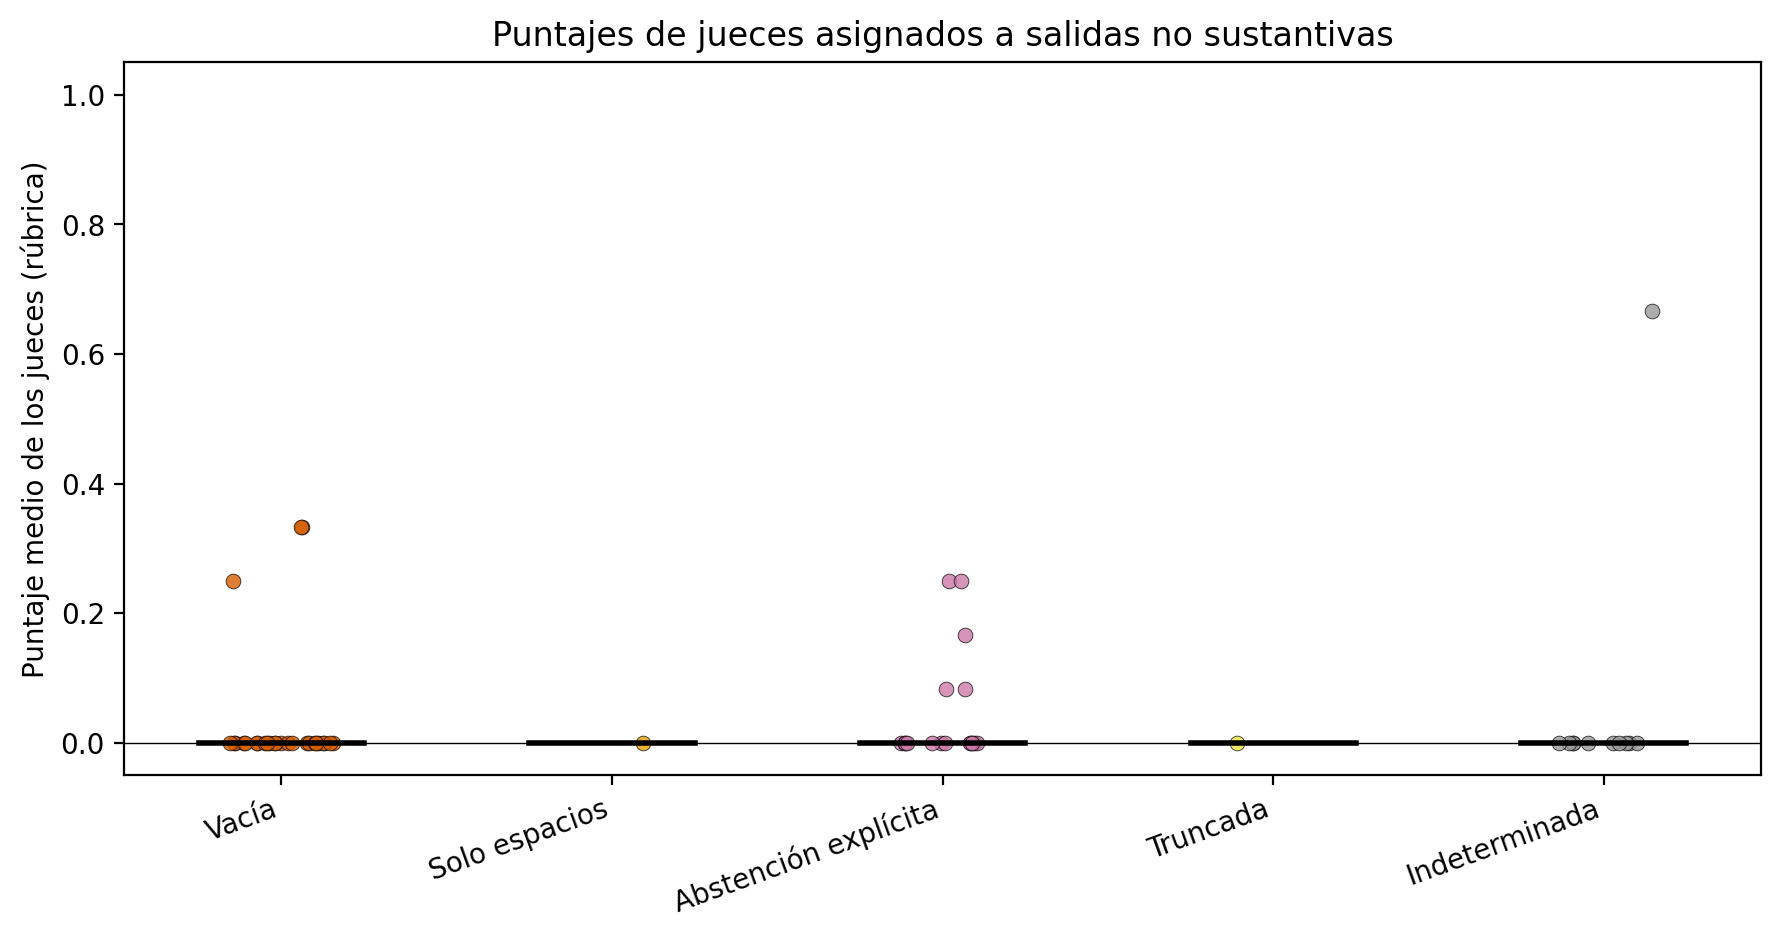

05_logs_tokens_y_recuperacion_nano.png


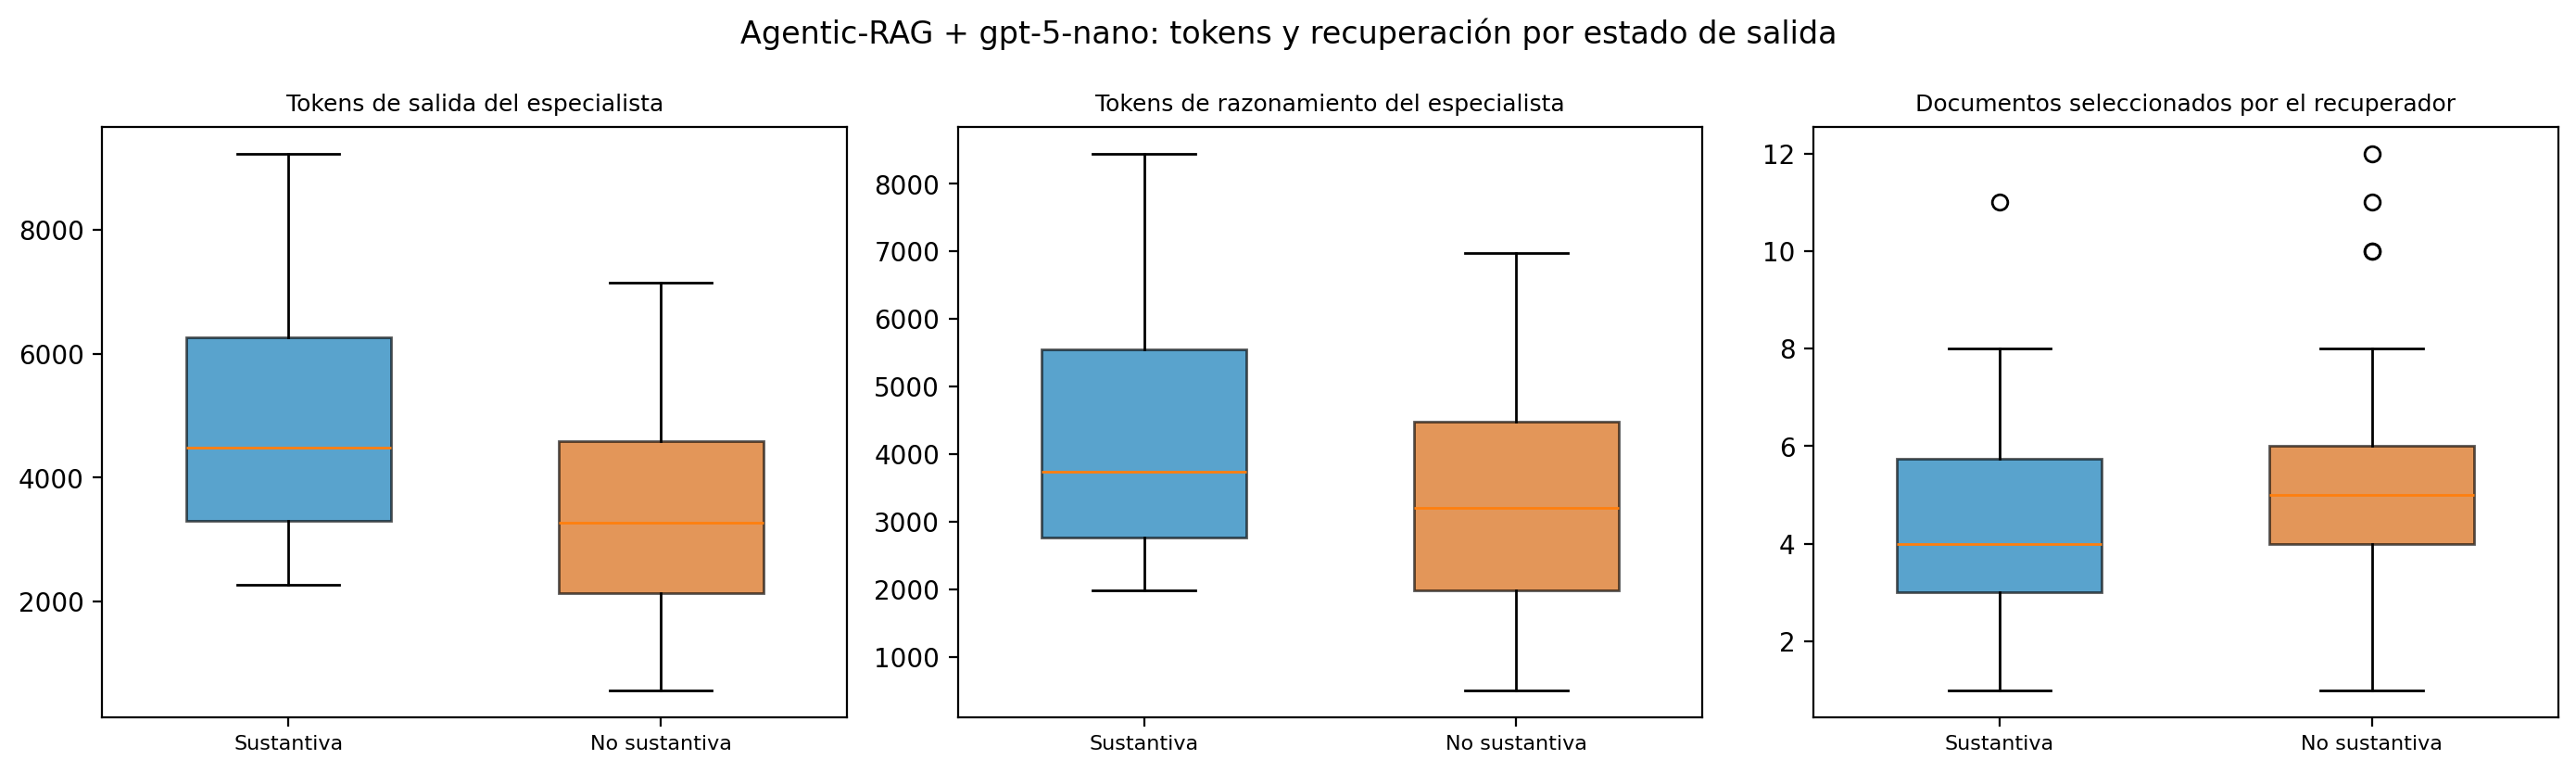

06_escenarios_nano.png


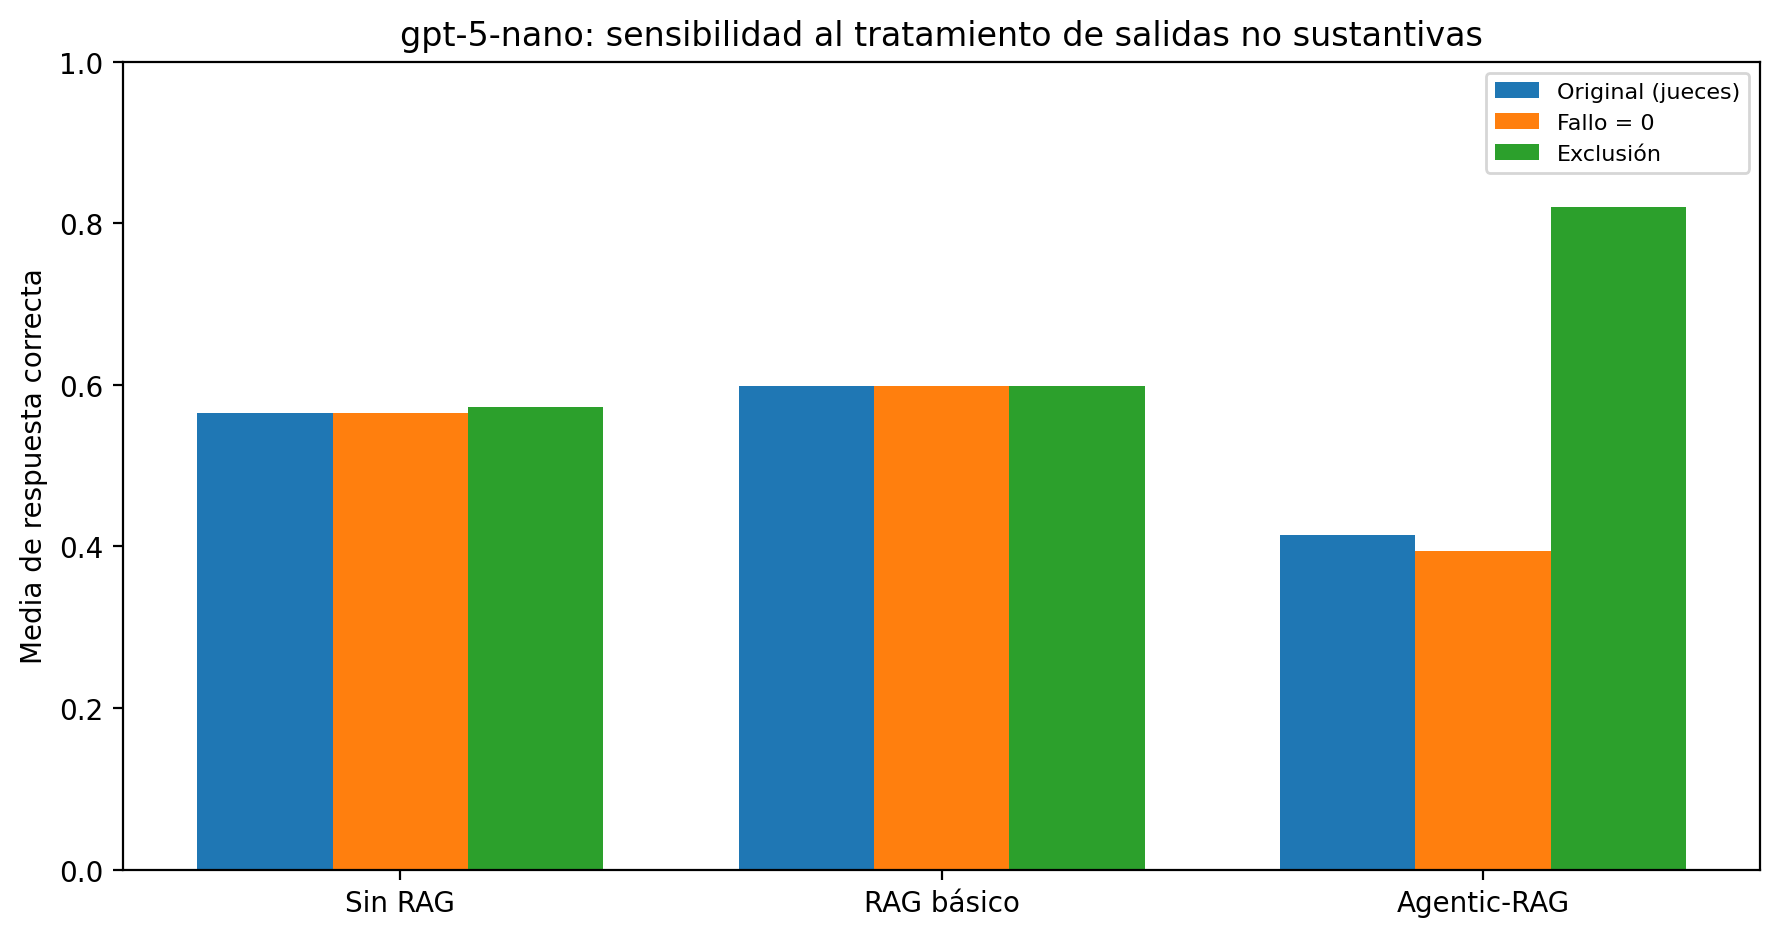

07_sim_rag_nano_vs_mini.png


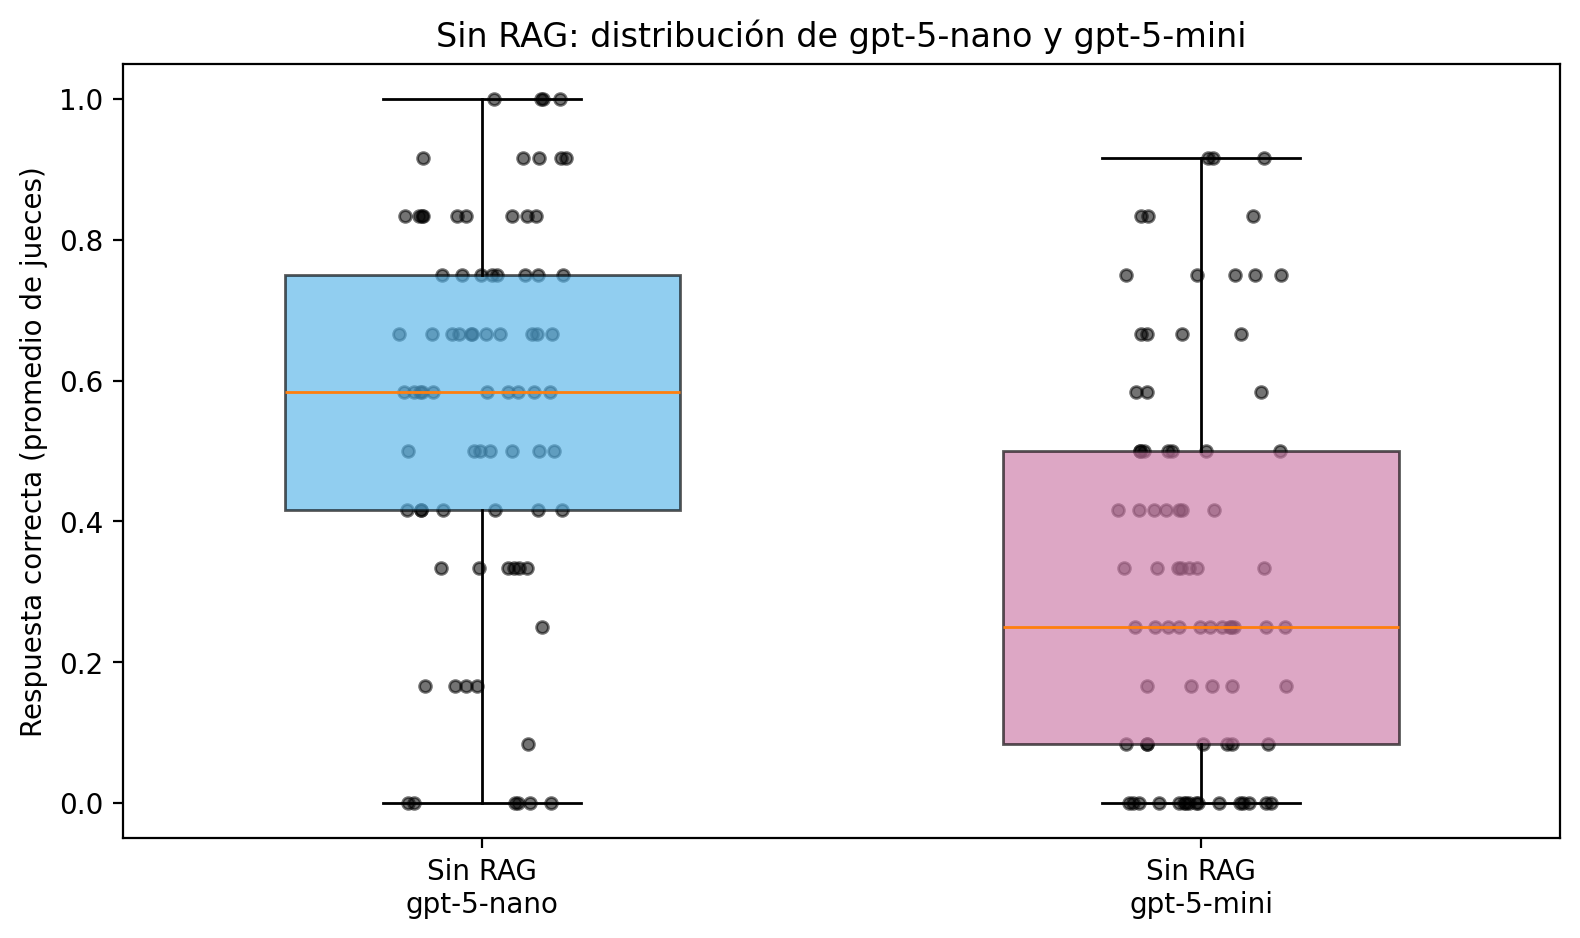

In [12]:
from IPython.display import Image, display
for name in [
    '01_composicion_respuestas_por_celda.png',
    '02_tasas_fallo_por_celda.png',
    '03_estados_nano_agentic.png',
    '04_puntajes_jueces_salidas_no_sustantivas.png',
    '05_logs_tokens_y_recuperacion_nano.png',
    '06_escenarios_nano.png',
    '07_sim_rag_nano_vs_mini.png',
]:
    print(name)
    display(Image(filename=str(dg.FIGURAS / name)))


## 11. Lectura para la revisión

- `salidas/11_celda_nano_agentic_79.csv` contiene las 79 filas de la celda con evidencia textual, log y escenarios.
- `salidas/04_auditoria_faltantes_join.csv` contiene las 27 medias recuperadas.
- `salidas/05_auditoria_jueces_salidas_no_sustantivas.csv` contiene las 171 evaluaciones de jueces sobre salidas no sustantivas.
- `revision_manual/paquete_revision_ciega.csv` es el paquete ciego para revisar manualmente todas las no sustantivas y 30 controles sustantivos.
- `revision_manual/LEEME.md` explica cómo completar la revisión.
- `INFORME_DIAGNOSTICO.md` y `PROPUESTAS_MANUSCRITO.md` contienen la interpretación y los cambios sugeridos.
